# Sales Data Analysis

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv(r"data/customers.csv")
df.head(4)

,customer_id,customer_segment,region,city,signup_date,loyalty_tier
0,1,Small Business,West,Ahmedabad,2023-12-20,Bronze
1,2,Consumer,East,Guwahati,2021-12-03,Silver
2,3,Small Business,Central,Nagpur,2023-12-23,Silver
3,4,Small Business,West,Pune,2023-01-09,NaN


In [3]:
df.shape

(50000, 6)

**Plot Customer Type Count**

<Axes: xlabel='count', ylabel='customer_segment'>

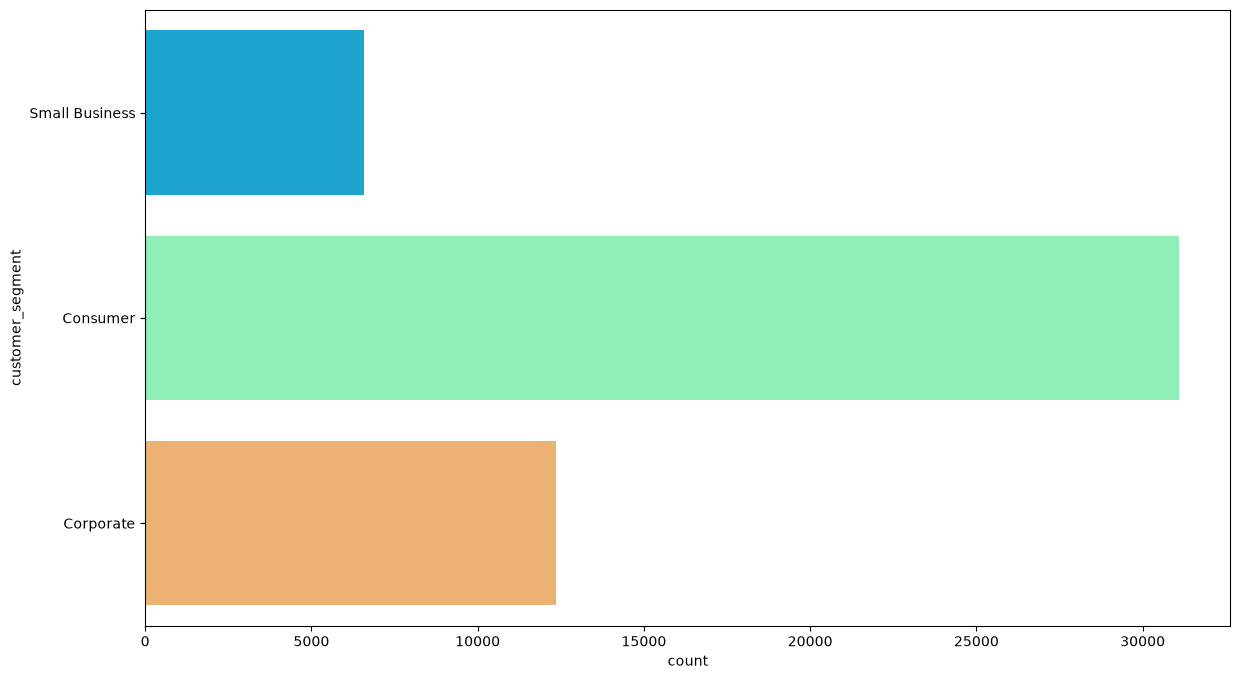

In [4]:
customer_type_plot = plt.figure(figsize=(14,8), dpi=100)
sns.countplot(data=df, y="customer_segment", hue="customer_segment", palette="rainbow")

**Find which type of customer are most loyal loyalty**

In [5]:
customer_loyality_df = df.copy()

In [6]:
customer_loyality_df["loyalty_tier"].unique()

<StringArray>
['Bronze', 'Silver', nan, 'Gold', 'Platinum']
Length: 5, dtype: str

In [7]:
def loyality_num(loyality):
    loyality = str(loyality)
    if loyality == "Bronze":
        return 25
    elif loyality == "Silver":
        return 50
    elif loyality == "Gold":
        return 75
    elif loyality == "Platinum":
        return 100
    return 0

customer_loyality_df["loyalty_num"] = customer_loyality_df["loyalty_tier"].apply(loyality_num)
customer_loyality_df["loyalty_num"] = customer_loyality_df["loyalty_num"].astype(dtype=int)
customer_loyality_df

,customer_id,customer_segment,region,city,signup_date,loyalty_tier,loyalty_num
0,1,Small Business,West,Ahmedabad,2023-12-20,Bronze,25
1,2,Consumer,East,Guwahati,2021-12-03,Silver,50
2,3,Small Business,Central,Nagpur,2023-12-23,Silver,50
3,4,Small Business,West,Pune,2023-01-09,NaN,0
4,5,Corporate,North,Delhi,2019-11-01,Gold,75
...,...,...,...,...,...,...,...
49995,49996,Consumer,West,Pune,2020-12-23,Platinum,100
49996,49997,Consumer,East,Kolkata,2023-10-31,Gold,75
49997,49998,Consumer,Central,Indore,2020-12-18,Gold,75
49998,49999,Consumer,East,Bhubaneswar,2020-04-19,Bronze,25


<Axes: xlabel='customer_segment', ylabel='loyalty_num'>

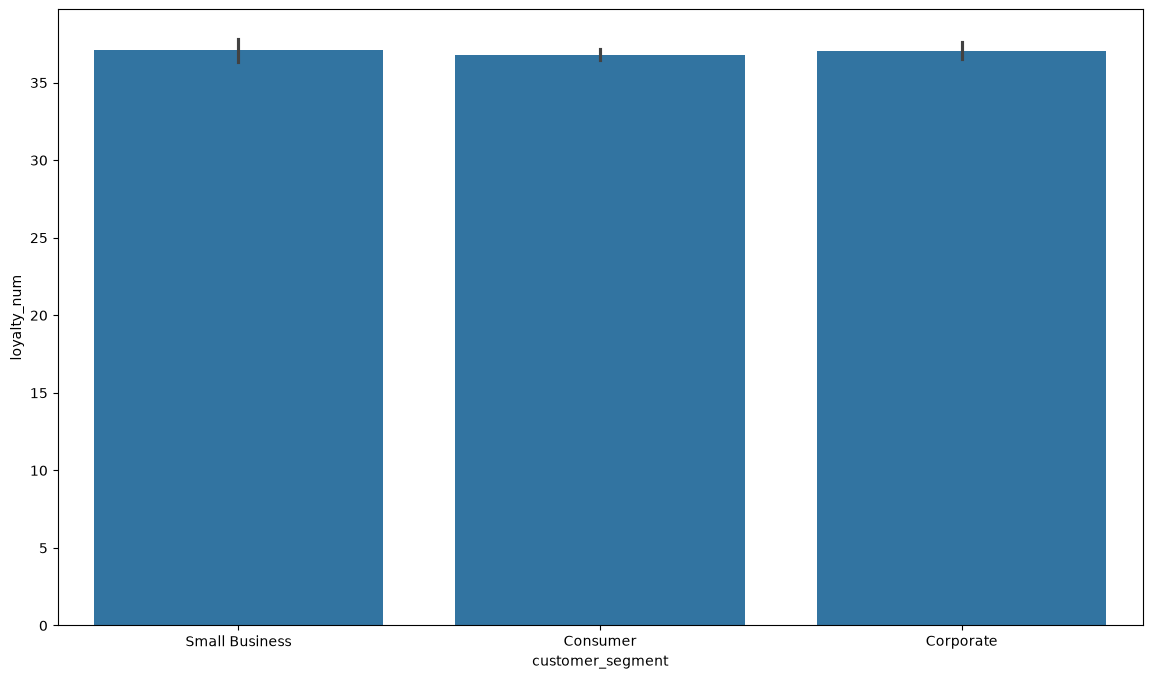

In [8]:
customer_loyality_fig = plt.figure(figsize=(14,8), dpi=100)
sns.barplot(data=customer_loyality_df, x="customer_segment", y="loyalty_num", estimator=np.mean)

In [ ]:
print(customer_loyality_df[df["customer_segment"] == "Small Business"]["loyalty_num"].mean())
print(customer_loyality_df[df["customer_segment"] == "Consumer"]["loyalty_num"].mean())
print(customer_loyality_df[df["customer_segment"] == "Corporate"]["loyalty_num"].mean())
# Their loyality score is really close so it is hard to indentify in the plot, but Small Business are the most loyal ones.

37.136882129277566
36.79451702168737
37.05556005507411
